# 05 · Analysis of results

**Purpose**: turn the cached predictions into the final, tested findings.

| Step | Question |
|---|---|
| 3–4 | Final accuracy of every method, with 95% CIs |
| 5 | Which differences are significant? (Holm-corrected) |
| 6 | Where does each method gain or lose? (by question type) |
| 7 | **H3**: does the gain grow with reasoning depth, controlling for type? |
| 8 | **H4**: does the grounding score measure real grounding? (scene graphs) |
| 9 | **When to trust an answer**: calibration and abstention with decomposed confidence |
| 10 | Failure analysis: confident but ungrounded answers |

**Protocols**
- *Pre-specified*: weights tuned on val (notebook 04).
- *Cross-validated*: weights tuned on testdev with 5 **fixed** image-grouped folds (saved in `data/cv_folds.csv`).

**Runtime:** CPU.

## 1 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.utils import load_config, set_seed
from src.errorlog import log_error
from src.gitsync import save_and_push

cfg = load_config()
set_seed(cfg["seed"])
SEED, DATA = cfg["seed"], cfg["paths"]["data"]

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr


In [2]:
import importlib, os, json, gzip, re, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from PIL import Image
import src.paths as P, src.aggregate as A, src.evaluate as E, src.cwmpvr as CW
for m in (P, A, E, CW):
    importlib.reload(m)

ORANGE, BLUE, AQUA, VIOLET, GREY, INK, MUTED = "#eb6834", "#2a78d6", "#1baf7a", "#6250d6", "#b9b8b2", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
def savefig(name):
    plt.savefig(f"figures/{name}.png"); plt.show()

## 2 · Load predictions, paths and fixed folds
- Folds are assigned **once** by image with a fixed seed and saved → every CV result is exactly reproducible (fixes the small 04 vs 04b difference, ERROR_LOG E05).

In [3]:
read = lambda f: pd.read_csv(f, dtype={"id": str, "imageId": str})
meta = {"eval": read("data/eval_testdev.csv").set_index("id"), "calib": read("data/calib_val.csv").set_index("id")}
GOLD = {s: meta[s]["answer"].map(P.normalize) for s in meta}
IDS = GOLD["eval"].index
Q, PTH = {}, {}
for s in meta:
    Q[s], PTH[s] = A.load_paths(f"results/paths_{s}.jsonl.gz")
    Q[s] = Q[s].set_index("id")
P03 = pd.read_csv("results/03_predictions_eval.csv", dtype=str, keep_default_na=False).set_index("id")
PARAMS = json.load(open("results/04_params.json"))
IMG = meta["eval"].loc[IDS, "imageId"].values

FOLD_FILE = "data/cv_folds.csv"
if not os.path.exists(FOLD_FILE):
    imgs = np.random.default_rng(SEED).permutation(sorted(meta["eval"].imageId.unique()))
    pd.DataFrame({"imageId": imgs, "fold": np.arange(len(imgs)) % 5}).to_csv(FOLD_FILE, index=False)
FOLD = meta["eval"].loc[IDS, "imageId"].map(read(FOLD_FILE).set_index("imageId")["fold"])
print(FOLD.value_counts().sort_index().rename("questions per fold").to_dict())

if "CV folds" not in open("ERROR_LOG.md").read():
    log_error(
        where="04 / 04b cross-validation (CV folds)",
        error="The same cross-validation gave 41.16% (notebook 04) and 41.32% (notebook 04b)",
        cause="Folds were regenerated in each notebook; the assignment of equally sized image groups to folds differed between runs",
        fix="A seeded image-to-fold assignment is saved once to data/cv_folds.csv and used for every CV result in notebook 05",
        lesson="Store CV folds as data, not as code that re-creates them",
    )

{0: 495, 1: 481, 2: 544, 3: 494, 4: 486}
Logged as E05:
### E05 (2026-10-25)
- **Where**: 04 / 04b cross-validation (CV folds)
- **Error**: `The same cross-validation gave 41.16% (notebook 04) and 41.32% (notebook 04b)`
- **Cause**: Folds were regenerated in each notebook; the assignment of equally sized image groups to folds differed between runs
- **Fix**: A seeded image-to-fold assignment is saved once to data/cv_folds.csv and used for every CV result in notebook 05
- **Lesson**: Store CV folds as data, not as code that re-creates them



## 3 · Final predictions for every method
- **Cross-validated** methods re-tune β, γ on 4 folds and predict the 5th, with the fixed folds.
- Oracle = the right answer appears in at least one path (upper bound for any voting rule).

In [4]:
BETAS, GAMMAS = [0, 0.25, 0.5, 1, 2, 4, 8], [0, 0.25, 0.5, 1, 2, 4, 8, 16]
pe = PTH["eval"]

def cross_validate(betas, gammas, grounding="itm"):
    out, chosen = [], []
    for f in range(5):
        tr, te = IDS[FOLD.values != f], IDS[FOLD.values == f]
        b = CW.select(CW.grid_search(pe[pe.id.isin(tr)], GOLD["eval"].loc[tr], betas, gammas, grounding))
        chosen.append((float(b.beta), float(b.gamma)))
        out.append(CW.cw_mpvr(pe[pe.id.isin(te)], b.beta, b.gamma, grounding))
    return pd.concat(out).reindex(IDS), chosen

cv_out, chosen = {}, {}
for name, (bs, gs) in {"Answer-only (CV)": (BETAS, [0]), "Grounding-only (CV)": ([0], GAMMAS),
                       "CW-MPVR (CV)": (BETAS, GAMMAS)}.items():
    cv_out[name], chosen[name] = cross_validate(bs, gs)
    print(f"{name:20s} (β, γ) per fold: {chosen[name]}")

v = PARAMS["CW-MPVR"]
PRED = pd.DataFrame({
    "Greedy": Q["eval"]["greedy"],
    "Majority vote": A.majority(pe)["answer"],
    "Answer-only": A.answer_only(pe)["answer"],
    "CW-MPVR (val-tuned)": CW.cw_mpvr(pe, v["beta"], v["gamma"])["answer"],
    **{k: o["answer"] for k, o in cv_out.items()},
    "LXMERT": P03["LXMERT"],
}).reindex(IDS)
CORRECT = PRED.eq(GOLD["eval"], axis=0)
ok_path = pe.answer.values == GOLD["eval"].reindex(pe.id).values
CORRECT["Oracle"] = pe.assign(ok=ok_path).groupby("id").ok.any().reindex(IDS)
PRED.to_csv("results/05_predictions_eval.csv")

Answer-only (CV)     (β, γ) per fold: [(1.0, 0.0), (0.5, 0.0), (1.0, 0.0), (0.5, 0.0), (1.0, 0.0)]
Grounding-only (CV)  (β, γ) per fold: [(0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, 0.0)]
CW-MPVR (CV)         (β, γ) per fold: [(2.0, 0.25), (2.0, 0.25), (0.0, 0.25), (2.0, 0.25), (2.0, 0.25)]


## 4 · Final results table

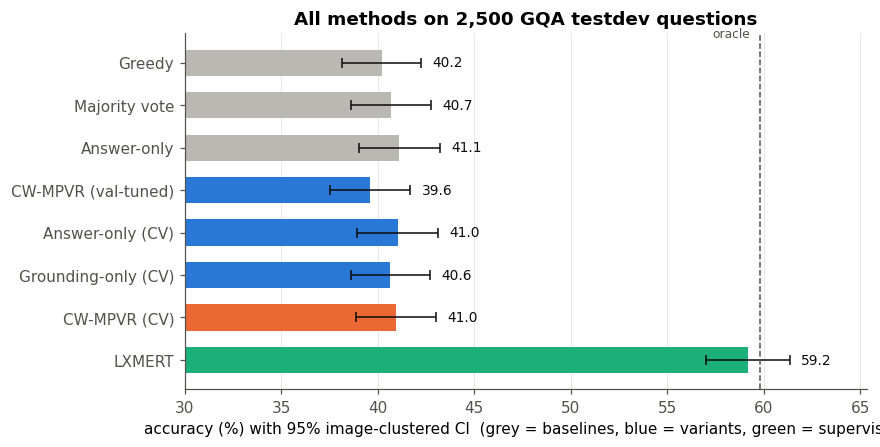

,accuracy,ci_low,ci_high
Greedy,40.20,38.16,42.23
Majority vote,40.68,38.62,42.74
Answer-only,41.12,39.01,43.22
CW-MPVR (val-tuned),39.60,37.51,41.66
Answer-only (CV),41.04,38.92,43.13
Grounding-only (CV),40.64,38.62,42.69
CW-MPVR (CV),40.96,38.89,42.99
LXMERT,59.20,56.99,61.35
Oracle,59.80,57.62,61.94


In [5]:
final = E.accuracy_table(CORRECT, IMG, SEED)
final.to_csv("results/05_final_accuracy.csv")

show = final.drop(index="Oracle")
col = {"Greedy": GREY, "Majority vote": GREY, "Answer-only": GREY, "LXMERT": AQUA,
       "CW-MPVR (CV)": ORANGE}
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(show))[::-1]
ax.barh(y, show.accuracy, color=[col.get(m, BLUE) for m in show.index], height=0.62)
ax.errorbar(show.accuracy, y, xerr=[show.accuracy - show.ci_low, show.ci_high - show.accuracy],
            fmt="none", ecolor=INK, capsize=3, linewidth=1)
for yi, a, hi in zip(y, show.accuracy, show.ci_high):
    ax.text(hi + 0.6, yi, f"{a:.1f}", va="center", fontsize=9, color=INK)
ax.axvline(final.loc["Oracle", "accuracy"], color=MUTED, linestyle="--", linewidth=1)
ax.text(final.loc["Oracle", "accuracy"] - 0.5, len(show) - 0.4, "oracle", ha="right", fontsize=8, color=MUTED)
ax.set_yticks(y, show.index); ax.grid(axis="y", visible=False)
ax.set_xlim(30, max(show.ci_high.max(), final.loc["Oracle", "accuracy"]) + 4)
ax.set_xlabel("accuracy (%) with 95% image-clustered CI  (grey = baselines, blue = variants, green = supervised)")
ax.set_title("All methods on 2,500 GQA testdev questions")
savefig("05_final_accuracy")
final

## 5 · Significance with multiple-comparison correction
- One family of 8 planned comparisons; p-values Holm-corrected so the chance of **any** false positive stays ≤ 5%.
- McNemar (exact, question-level) and paired bootstrap (resamples images; accounts for shared images).

In [6]:
def compare(a, b, mask=None):
    m = np.ones(len(CORRECT), bool) if mask is None else mask
    bs = E.paired_bootstrap(CORRECT[a].values[m], CORRECT[b].values[m], IMG[m], seed=SEED)
    mc = E.mcnemar(CORRECT[a].values[m], CORRECT[b].values[m])
    return {"A": a, "B": b, "A − B (pts)": 100 * bs["diff"], "CI low": 100 * bs["ci_lo"],
            "CI high": 100 * bs["ci_hi"], "only A": mc["only_A"], "only B": mc["only_B"],
            "p McNemar": mc["p_mcnemar"], "p bootstrap": bs["p_boot"]}

def holm(df):
    for c in ("p McNemar", "p bootstrap"):
        df[c + " (Holm)"] = multipletests(df[c], method="holm")[1]
    return df

PAIRS = [("CW-MPVR (CV)", "Greedy"), ("CW-MPVR (CV)", "Majority vote"), ("CW-MPVR (CV)", "Answer-only"),
         ("CW-MPVR (CV)", "Answer-only (CV)"), ("Grounding-only (CV)", "Answer-only (CV)"),
         ("CW-MPVR (val-tuned)", "Majority vote"), ("Majority vote", "Greedy"), ("LXMERT", "CW-MPVR (CV)")]
tests = holm(pd.DataFrame([compare(a, b) for a, b in PAIRS]))
tests.to_csv("results/05_tests.csv", index=False)
tests.round(4)

,A,B,A − B (pts),CI low,CI high,only A,only B,p McNemar,p bootstrap,p McNemar (Holm),p bootstrap (Holm)
0,CW-MPVR (CV),Greedy,0.76,-0.3727,1.9271,95,76,0.1685,0.2100,0.8424,1.0000
1,CW-MPVR (CV),Majority vote,0.28,-0.2816,0.8884,30,23,0.4101,0.3668,1.0000,1.0000
2,CW-MPVR (CV),Answer-only,-0.16,-0.6792,0.3654,18,22,0.6358,0.5864,1.0000,1.0000
3,CW-MPVR (CV),Answer-only (CV),-0.08,-0.6236,0.4766,21,23,0.8804,0.8336,1.0000,1.0000
4,Grounding-only (CV),Answer-only (CV),-0.40,-0.8789,0.0813,13,23,0.1325,0.1228,0.7950,0.7476
5,CW-MPVR (val-tuned),Majority vote,-1.08,-2.3566,0.1670,100,127,0.0842,0.1068,0.5893,0.7476
6,Majority vote,Greedy,0.48,-0.6784,1.6387,94,82,0.4071,0.4532,1.0000,1.0000
7,LXMERT,CW-MPVR (CV),18.24,15.7726,20.7132,668,212,0.0000,0.0000,0.0000,0.0000


## 6 · Results by question type
- Accuracy per structural type, and the CW-MPVR (CV) gain over majority vote with a 95% CI.
- 5 tests → Holm-corrected.

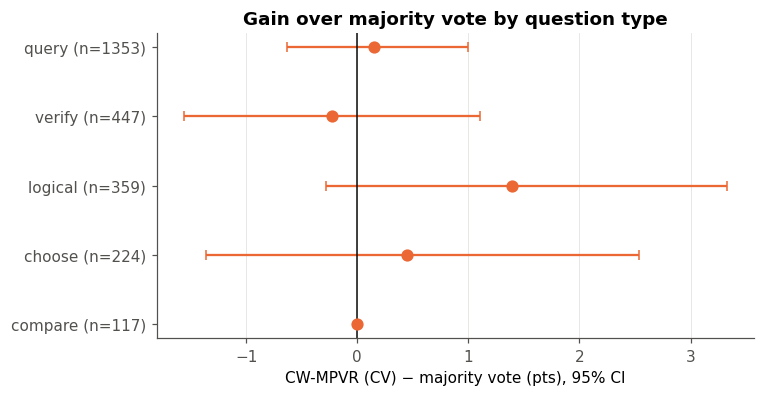

,Greedy,Majority vote,CW-MPVR (CV),LXMERT,n
query,27.3,27.9,28.1,45.1,1353
verify,58.6,56.8,56.6,78.7,447
logical,60.4,61.8,63.2,75.8,359
choose,43.8,46.4,46.9,76.8,224
compare,50.4,50.4,50.4,63.2,117


,type,A − B (pts),CI low,CI high,p McNemar,p McNemar (Holm)
0,query,0.1478,-0.6325,0.9954,0.8555,1.0000
1,verify,-0.2237,-1.5590,1.1038,1.0000,1.0000
2,logical,1.3928,-0.2778,3.3241,0.1797,0.8984
3,choose,0.4464,-1.3575,2.5316,1.0000,1.0000
4,compare,0.0000,0.0000,0.0000,1.0000,1.0000


In [7]:
stype = meta["eval"].loc[IDS, "structural"].values
main = ["Greedy", "Majority vote", "CW-MPVR (CV)", "LXMERT"]
by_type = (CORRECT[main].groupby(stype).mean() * 100).round(1)
by_type["n"] = pd.Series(stype).value_counts()
by_type = by_type.sort_values("n", ascending=False)

gains = holm(pd.DataFrame([{"type": t, **compare("CW-MPVR (CV)", "Majority vote", stype == t)} for t in by_type.index]))
gains.to_csv("results/05_gain_by_type.csv", index=False)
by_type.to_csv("results/05_accuracy_by_type.csv")

fig, ax = plt.subplots(figsize=(7, 3.6))
yy = np.arange(len(gains))[::-1]
ax.errorbar(gains["A − B (pts)"], yy, xerr=[gains["A − B (pts)"] - gains["CI low"], gains["CI high"] - gains["A − B (pts)"]],
            fmt="o", color=ORANGE, ecolor=ORANGE, capsize=3, markersize=7, linewidth=1.5)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(yy, [f"{t} (n={n})" for t, n in zip(gains.type, by_type.n)])
ax.grid(axis="y", visible=False)
ax.set_xlabel("CW-MPVR (CV) − majority vote (pts), 95% CI")
ax.set_title("Gain over majority vote by question type")
savefig("05_gain_by_type")
display(by_type)
gains[["type", "A − B (pts)", "CI low", "CI high", "p McNemar", "p McNemar (Holm)"]].round(4)

## 7 · H3: does the gain grow with reasoning depth?
- Depth = steps in the GQA program; 5+ pooled (few questions).
- Depth and type are linked (notebook 01) → the regression **controls for type**, with standard errors clustered by image.
- Outcome: per-question gain $d = \text{correct}_{\text{CW-MPVR}} - \text{correct}_{\text{majority}} \in \{-1, 0, 1\}$.

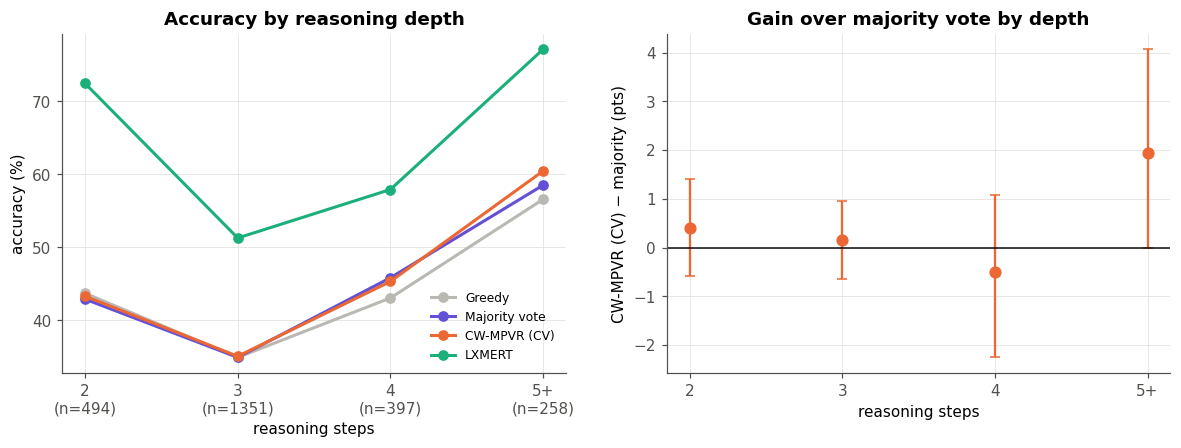

,odds ratio per extra step,p
Majority vote,1.0105,0.8730
CW-MPVR (CV),0.9945,0.9334
LXMERT,0.9697,0.6125


,gain change per extra step (pts),CI low,CI high,p,n
all types (type fixed effects),-0.3565,-1.0576,0.3447,0.319,2500.0
logical only (depth 4-9),-0.0228,-0.8153,0.7696,0.955,359.0


In [8]:
dep = meta["eval"].loc[IDS, "n_steps"].values
dbin = pd.Series(np.where(dep >= 5, "5+", dep.astype(str)), index=IDS)
order = sorted(dbin.unique(), key=lambda s: int(s.rstrip("+")))

acc_d = (CORRECT[main].groupby(dbin).mean() * 100).reindex(order)
n_d = dbin.value_counts().reindex(order)
gain_d = pd.DataFrame([compare("CW-MPVR (CV)", "Majority vote", (dbin == b).values) for b in order], index=order)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for m, c in zip(main, [GREY, VIOLET, ORANGE, AQUA]):
    axes[0].plot(range(len(order)), acc_d[m].values, "-o", color=c, linewidth=2, markersize=6, label=m)
axes[0].set_xticks(range(len(order)), [f"{b}\n(n={n_d[b]})" for b in order])
axes[0].set_xlabel("reasoning steps"); axes[0].set_ylabel("accuracy (%)")
axes[0].set_title("Accuracy by reasoning depth"); axes[0].legend(fontsize=8)
g = gain_d["A − B (pts)"]
axes[1].errorbar(range(len(order)), g, yerr=[g - gain_d["CI low"], gain_d["CI high"] - g],
                 fmt="o", color=ORANGE, ecolor=ORANGE, capsize=3, markersize=7)
axes[1].axhline(0, color=INK, linewidth=1)
axes[1].set_xticks(range(len(order)), order)
axes[1].set_xlabel("reasoning steps"); axes[1].set_ylabel("CW-MPVR (CV) − majority (pts)")
axes[1].set_title("Gain over majority vote by depth")
savefig("05_depth")

reg = pd.DataFrame({"d": (CORRECT["CW-MPVR (CV)"].astype(int) - CORRECT["Majority vote"].astype(int)).values,
                    "steps": dep, "type": stype, "img": pd.factorize(IMG)[0]})
cl = lambda df: {"cov_type": "cluster", "cov_kwds": {"groups": df["img"]}}
fits = {
    "all types (type fixed effects)": smf.ols("d ~ steps + C(type)", reg).fit(**cl(reg)),
    "logical only (depth 4-9)": smf.ols("d ~ steps", reg[reg.type == "logical"]).fit(**cl(reg[reg.type == "logical"])),
}
h3 = pd.DataFrame({k: {"gain change per extra step (pts)": 100 * f.params["steps"],
                       "CI low": 100 * f.conf_int().loc["steps", 0], "CI high": 100 * f.conf_int().loc["steps", 1],
                       "p": f.pvalues["steps"], "n": int(f.nobs)} for k, f in fits.items()}).T
h3.to_csv("results/05_h3_depth.csv")

difficulty = {}
for m in ["Majority vote", "CW-MPVR (CV)", "LXMERT"]:
    df = reg.assign(y=CORRECT[m].astype(int).values)
    f = smf.logit("y ~ steps + C(type)", df).fit(disp=0, **cl(df))
    difficulty[m] = {"odds ratio per extra step": np.exp(f.params["steps"]), "p": f.pvalues["steps"]}
display(pd.DataFrame(difficulty).T.round(4))
h3.round(4)

## 8 · H4: does the grounding score measure real grounding?
- Uses val (calibration) images, the only ones with public scene graphs.
- For each evidence sentence: share of its content words that name an object or attribute present in the image's scene graph (**object precision**).
- If ITM measures grounding, paths whose evidence matches the scene graph should get higher ITM.
- Caveat: val images were seen in BLIP-2 pretraining (notebook 04) → this is an upper bound on how well ITM tracks grounding.

4,371 evidence sentences | ITM all-match vs none-match: Mann-Whitney p = 4.76e-61


,n,mean_ITM,path_accuracy
match,,,
none,1317,0.251,0.343
partial,1458,0.426,0.350
all,1596,0.396,0.480


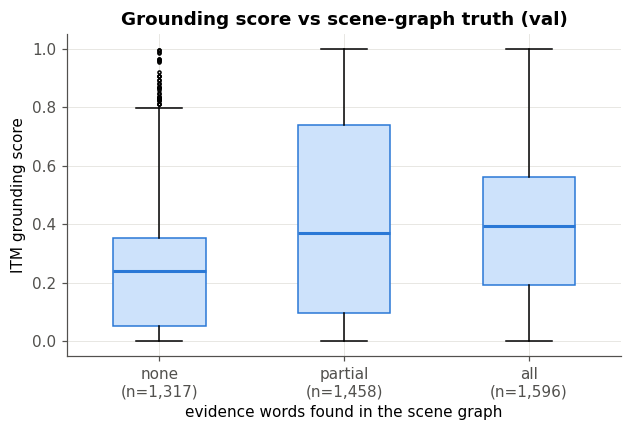

,Spearman ρ with object precision,p
ITM,0.2159,0.0
ITC,0.3348,0.0


In [9]:
sg = json.load(open(f"{DATA}/raw/val_sceneGraphs.json"))
STOP = set("the and with this that there their its are image picture photo some near next front behind side top bottom left right".split())

def words(text):
    return {w[:-1] if len(w) > 3 and w.endswith("s") else w
            for w in re.findall(r"[a-z]+", text.lower()) if len(w) > 2 and w not in STOP}

vocab = {}
def image_vocab(img):
    if img not in vocab:
        objs = sg.get(img, {"objects": {}})["objects"].values()
        vocab[img] = words(" ".join(o["name"] + " " + " ".join(o["attributes"]) for o in objs))
    return vocab[img]

rows = []
with gzip.open("results/paths_calib.jsonl.gz", "rt") as f:
    for line in f:
        r = json.loads(line)
        img = meta["calib"].loc[r["id"], "imageId"]
        for p in r["paths"]:
            w = words(p["evidence"])
            if w:
                rows.append({"id": r["id"], "itm": p["itm"], "itc": p["itc"],
                             "precision": len(w & image_vocab(img)) / len(w),
                             "correct": P.normalize(p["answer"]) == GOLD["calib"][r["id"]]})
h4 = pd.DataFrame(rows)
h4["match"] = pd.cut(h4.precision, [-0.01, 0, 0.999, 1], labels=["none", "partial", "all"])

rho_itm = spearmanr(h4.itm, h4.precision); rho_itc = spearmanr(h4.itc, h4.precision)
mw = mannwhitneyu(h4.itm[h4.match == "all"], h4.itm[h4.match == "none"])
summary_h4 = pd.DataFrame({
    "ITM": {"Spearman ρ with object precision": rho_itm.statistic, "p": rho_itm.pvalue},
    "ITC": {"Spearman ρ with object precision": rho_itc.statistic, "p": rho_itc.pvalue},
}).T
print(f"{len(h4):,} evidence sentences | ITM all-match vs none-match: Mann-Whitney p = {mw.pvalue:.2e}")
display(h4.groupby("match", observed=True).agg(n=("itm", "size"), mean_ITM=("itm", "mean"),
                                               path_accuracy=("correct", "mean")).round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
groups = [h4.itm[h4.match == k] for k in ["none", "partial", "all"]]
ax.boxplot(groups, widths=0.5, patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=BLUE, linewidth=2), flierprops=dict(markersize=2))
ax.set_xticks([1, 2, 3], [f"{k}\n(n={len(g):,})" for k, g in zip(["none", "partial", "all"], groups)])
ax.set_xlabel("evidence words found in the scene graph"); ax.set_ylabel("ITM grounding score")
ax.set_title("Grounding score vs scene-graph truth (val)")
savefig("05_h4_scene_graph")
summary_h4.to_csv("results/05_h4.csv")
summary_h4.round(4)

## 9 · When to trust an answer: calibration and abstention
- Notebook 02 found that answer confidence predicts **whether** a question is answered correctly, not which path is right.
- Here each signal scores the **final** CW-MPVR (CV) answer; a logistic model combines them (fitted out-of-fold with the same folds).
- **AUROC**: separates right from wrong answers (0.5 = chance). **ECE**: gap between stated confidence and actual accuracy (lower is better). **AURC**: average error when answering only the most confident questions first (lower is better).

In [10]:
feat = CW.question_features(pe, cv_out["CW-MPVR (CV)"]).reindex(IDS)
y = CORRECT["CW-MPVR (CV)"].astype(int).values
X_all = pd.DataFrame({"agreement": feat.agreement, "answer": feat.answer_conf,
                      "grounding": np.log(np.clip(feat.grounding_conf, 1e-6, 1))}).values

def oof_logistic(cols):
    out = np.zeros(len(y))
    for f in range(5):
        tr, te = FOLD.values != f, FOLD.values == f
        Xtr, Xte = X_all[tr][:, cols], X_all[te][:, cols]
        mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
        m = LogisticRegression().fit((Xtr - mu) / sd, y[tr])
        out[te] = m.predict_proba((Xte - mu) / sd)[:, 1]
    return out

SCORES = {
    "Agreement (self-consistency)": feat.agreement.values,
    "Answer confidence": np.exp(feat.answer_conf.values),
    "Grounding confidence": feat.grounding_conf.values,
    "Agreement + answer": oof_logistic([0, 1]),
    "Agreement + grounding": oof_logistic([0, 2]),
    "All three (decomposed)": oof_logistic([0, 1, 2]),
}

def ece(conf, yy, bins=10):
    idx = np.minimum((conf * bins).astype(int), bins - 1)
    return sum(abs(yy[idx == b].mean() - conf[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any())

def risk_coverage(conf, yy):
    o = np.argsort(-conf, kind="stable")
    acc = np.cumsum(yy[o]) / np.arange(1, len(yy) + 1)
    return np.arange(1, len(yy) + 1) / len(yy), acc

calib_tbl = {}
for k, s in SCORES.items():
    cov, acc = risk_coverage(s, y)
    calib_tbl[k] = {"AUROC": roc_auc_score(y, s), "ECE": ece(s, y), "AURC": np.mean(1 - acc),
                    "accuracy @ 50% answered": 100 * acc[len(y) // 2 - 1]}
calib_tbl = pd.DataFrame(calib_tbl).T

# paired, image-clustered bootstrap: does adding answer + grounding beat agreement alone?
rng = np.random.default_rng(SEED)
codes, uniq = pd.factorize(IMG)
members = [np.where(codes == i)[0] for i in range(len(uniq))]
diffs = []
for _ in range(1000):
    idx = np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))])
    diffs.append(roc_auc_score(y[idx], SCORES["All three (decomposed)"][idx]) - roc_auc_score(y[idx], SCORES["Agreement (self-consistency)"][idx]))
diffs = np.array(diffs)
print(f"AUROC gain, all three vs agreement: {np.mean(diffs):+.4f}  95% CI [{np.quantile(diffs, .025):+.4f}, {np.quantile(diffs, .975):+.4f}]  "
      f"p = {min(1, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())):.4f}")
calib_tbl.to_csv("results/05_calibration.csv")
calib_tbl.round(4)

AUROC gain, all three vs agreement: +0.0459  95% CI [+0.0329, +0.0589]  p = 0.0000


,AUROC,ECE,AURC,accuracy @ 50% answered
Agreement (self-consistency),0.6814,0.3382,0.4813,54.16
Answer confidence,0.7036,0.3086,0.4329,55.44
Grounding confidence,0.4791,0.1756,0.6254,39.44
Agreement + answer,0.7274,0.0116,0.4215,58.16
Agreement + grounding,0.6765,0.0087,0.4875,54.00
All three (decomposed),0.7273,0.0161,0.4228,58.08


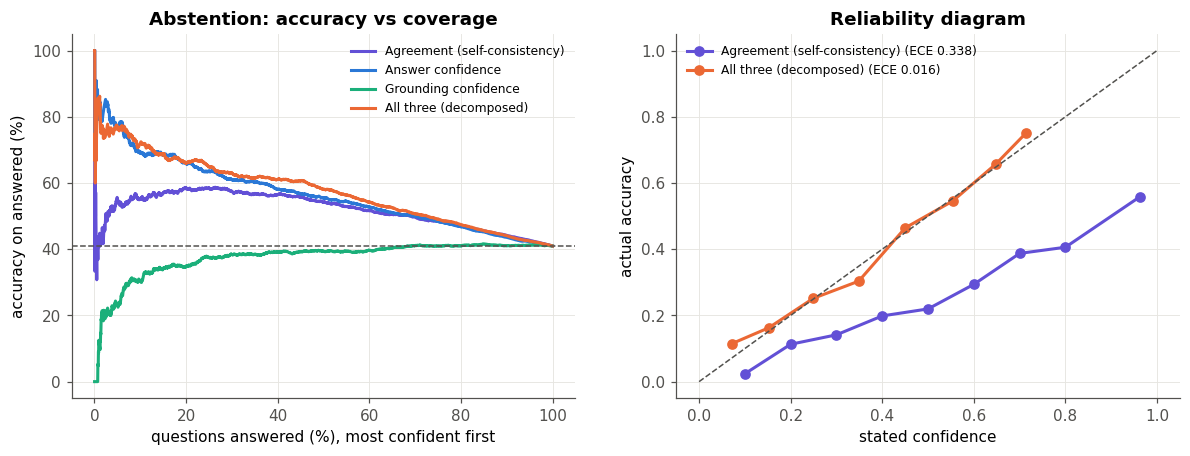

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for k, c in [("Agreement (self-consistency)", VIOLET), ("Answer confidence", BLUE),
             ("Grounding confidence", AQUA), ("All three (decomposed)", ORANGE)]:
    cov, acc = risk_coverage(SCORES[k], y)
    axes[0].plot(cov * 100, acc * 100, color=c, linewidth=2, label=k)
axes[0].axhline(100 * y.mean(), color=MUTED, linestyle="--", linewidth=1)
axes[0].set_xlabel("questions answered (%), most confident first"); axes[0].set_ylabel("accuracy on answered (%)")
axes[0].set_title("Abstention: accuracy vs coverage"); axes[0].legend(fontsize=8)

bins = np.linspace(0, 1, 11)
for k, c in [("Agreement (self-consistency)", VIOLET), ("All three (decomposed)", ORANGE)]:
    s = SCORES[k]; idx = np.minimum((s * 10).astype(int), 9)
    xs = [s[idx == b].mean() for b in range(10) if (idx == b).sum() >= 10]
    ys = [y[idx == b].mean() for b in range(10) if (idx == b).sum() >= 10]
    axes[1].plot(xs, ys, "-o", color=c, linewidth=2, markersize=6, label=f"{k} (ECE {ece(s, y):.3f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
axes[1].set_xlabel("stated confidence"); axes[1].set_ylabel("actual accuracy")
axes[1].set_title("Reliability diagram"); axes[1].legend(fontsize=8)
savefig("05_calibration")

## 10 · Failure analysis
- Split CW-MPVR (CV) answers by answer confidence and grounding confidence (each at its median).
- **High answer confidence + low grounding** = the model is sure, but its evidence does not match the image → candidate hallucinations.

n  accuracy
answer conf grounding               
high        high       548      56.0
            low        702      55.0
low         high       702      26.5
            low        548      26.5

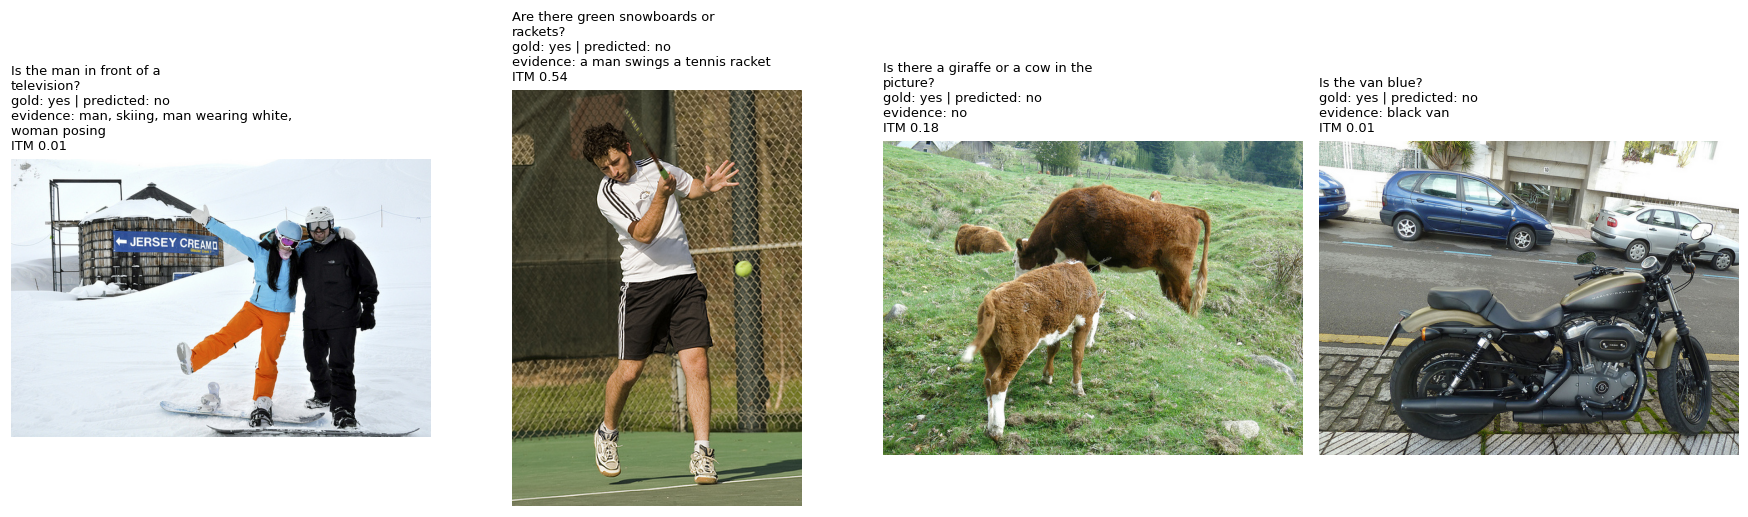

In [12]:
hiA = feat.answer_conf.values >= np.median(feat.answer_conf)
hiG = feat.grounding_conf.values >= np.median(feat.grounding_conf)
cells = pd.DataFrame({"answer conf": np.where(hiA, "high", "low"), "grounding": np.where(hiG, "high", "low"), "correct": y})
quad = cells.groupby(["answer conf", "grounding"]).correct.agg(n="size", accuracy="mean")
quad["accuracy"] = (100 * quad.accuracy).round(1)
quad.to_csv("results/05_failure_quadrants.csv")
display(quad)

ev = {}
with gzip.open("results/paths_eval.jsonl.gz", "rt") as f:
    for line in f:
        r = json.loads(line); ev[r["id"]] = r["paths"]

pick = feat[(hiA & ~hiG) & (y == 0)].sort_values("answer_conf", ascending=False).head(4).index
fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
for ax, qid in zip(axes, pick):
    pred = PRED.loc[qid, "CW-MPVR (CV)"]
    sup = [p for p in ev[qid] if P.normalize(p["answer"]) == pred]
    best = max(sup, key=lambda p: p["lp_mean"]) if sup else ev[qid][0]
    ax.imshow(Image.open(f"{DATA}/images/testdev/{meta['eval'].loc[qid, 'imageId']}.jpg"))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    q = "\n".join(textwrap.wrap(meta["eval"].loc[qid, "question"], 34))
    e = "\n".join(textwrap.wrap(best["evidence"], 34))
    ax.set_title(f"{q}\ngold: {GOLD['eval'][qid]} | predicted: {pred}\nevidence: {e}\nITM {best['itm']:.2f}",
                 fontsize=8.5, fontweight="normal", loc="left")
plt.tight_layout(); savefig("05_failures")

## 11 · Summary tables (small, copy-friendly)
- Prints only the short result tables of this notebook.

In [13]:
for f in ["05_final_accuracy", "05_tests", "05_gain_by_type", "05_h3_depth", "05_h4", "05_calibration", "05_failure_quadrants"]:
    print(f"\n=== {f}")
    print(pd.read_csv(f"results/{f}.csv").rename(columns={"Unnamed: 0": ""}).round(4).to_string(index=False))
print("\n=== CV (β, γ) per fold")
for k, v in chosen.items():
    print(f"{k:20s} {v}")


=== 05_final_accuracy
                     accuracy  ci_low  ci_high
             Greedy     40.20   38.16    42.23
      Majority vote     40.68   38.62    42.74
        Answer-only     41.12   39.01    43.22
CW-MPVR (val-tuned)     39.60   37.51    41.66
   Answer-only (CV)     41.04   38.92    43.13
Grounding-only (CV)     40.64   38.62    42.69
       CW-MPVR (CV)     40.96   38.89    42.99
             LXMERT     59.20   56.99    61.35
             Oracle     59.80   57.62    61.94

=== 05_tests
                  A                B  A − B (pts)  CI low  CI high  only A  only B  p McNemar  p bootstrap  p McNemar (Holm)  p bootstrap (Holm)
       CW-MPVR (CV)           Greedy         0.76 -0.3727   1.9271      95      76     0.1685       0.2100            0.8424              1.0000
       CW-MPVR (CV)    Majority vote         0.28 -0.2816   0.8884      30      23     0.4101       0.3668            1.0000              1.0000
       CW-MPVR (CV)      Answer-only        -0.16 -0.6792 

## Observations

**Accuracy (H1, H2)**
- CW-MPVR (CV) 41.0% vs majority 40.7% (+0.3 pts) and greedy 40.2%; no BLIP-2 comparison is significant after Holm correction.
- The CV result varied 40.96–41.32% across fold assignments (notebooks 04, 04b, 05) → the gain is within fold noise. Fixed folds (`data/cv_folds.csv`) make 05 the authoritative run.
- LXMERT (supervised) leads by 18.2 pts (p < 0.001); oracle 59.8% → path *selection* remains the bottleneck.

**Depth (H3): not supported**
- Gain does not grow with depth: −0.36 pts per extra step (95% CI −1.06 to 0.34, p = 0.32), type-controlled; within `logical` (depth 4–9) p = 0.96.
- After controlling for type, depth does not even predict accuracy (odds ratio ≈ 1.0 per step for all methods).

**Grounding validity (H4): supported**
- ITM rises when evidence names objects in the scene graph (Spearman ρ = 0.22, p < 0.001; mean ITM 0.25 no match vs 0.40 full match).
- Paths whose evidence fully matches the scene graph are more often correct (48% vs 34%).
- ITC tracks object presence even more closely (ρ = 0.33). Caveat: val images were seen in pretraining.

**When to trust an answer: a double dissociation**
- Question level: answer confidence separates right from wrong answers (AUROC 0.70); grounding does not (0.48).
- Path level (notebook 02/04): the reverse; grounding picks paths (AUC 0.54), answer confidence does not (0.51).
- Agreement + answer confidence beats agreement alone: AUROC 0.681 → 0.727 (+0.046, 95% CI 0.033–0.059, p < 0.001); answering the most confident half gives 58.1% vs 54.2%.
- Adding grounding on top changes nothing (0.7273 vs 0.7274).
- Fair comparisons are AUROC/AURC; low ECE of the fitted combinations partly reflects the logistic fit itself.

**Failures**
- Accuracy splits by answer confidence (56% vs 26.5%), not by grounding (56% vs 55%) → "confident but ungrounded" answers are not more often wrong at question level.

## 12 · Save to GitHub

In [ ]:
save_and_push("notebooks/05_analysis.ipynb", "Add final analysis: significance, depth, scene-graph grounding, calibration, failures")